# 01 — Lựa chọn đặc trưng (Feature Selection) — `[K1]` Tuần 6

**Đồ án CS315 — Nhóm 14** · Phụ trách: Nguyễn Duy Khang (`26410055`)

Notebook đóng gói kết quả lựa chọn đặc trưng chính thức cho bài toán dự báo lan truyền sóng ùn tắc khu vực Hàng Xanh. Mọi logic nằm trong module [`01_feature_selection_pipeline.py`](./01_feature_selection_pipeline.py); notebook chỉ gọi module, hiển thị và giải thích kết quả.

| Bước | Kỹ thuật | Ngưỡng |
| :--- | :--- | :--- |
| Biến SỐ | `MinMaxScaler` → `VarianceThreshold` | `0.01` |
| Biến ORD / NOM | `OrdinalEncoder` / `OneHotEncoder` → $\chi^2$ | $\chi^2 > 5.99$ ($df=2, \alpha=0.05$) |
| Xếp hạng | Mutual Information (bắt quan hệ phi tuyến) | — |
| Đa cộng tuyến (tập rút gọn ST-GNN) | Cặp $|r| \ge 0.9$ → bỏ biến MI thấp hơn, **không bỏ biến mưa/triều** | $0.9$ |
| Đối chứng | `StandardScaler` → `PCA` | 95% phương sai |

**Chống rò rỉ dữ liệu:** mọi bước học từ dữ liệu chỉ `fit` trên phần *train* của từng fold `TimeSeriesSplit` (5 fold, chia theo mốc thời gian duy nhất, purge `1/2/4` bước cho `t+15'/30'/60'`). Một đặc trưng được chốt nếu được chọn ở **đa số fold**.

**Sản phẩm (`results/`):** `selected_features.json`, `feature_importance_ranking.csv`, `feature_selection_report.csv`, `dimension_summary.csv`, `pearson_redundant_pairs.csv`.

## 1. Khởi tạo

In [1]:
import importlib
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Patch

# Tìm thư mục gốc repo (chạy được cả local lẫn Colab sau khi clone repo).
ROOT = Path.cwd().resolve()
while not (ROOT / "02_feature_selection").is_dir():
    if ROOT.parent == ROOT:
        raise FileNotFoundError("Hãy mở notebook từ bên trong repo cs315-traffic-congestion-graph-ml")
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "02_feature_selection"))
fs = importlib.import_module("01_feature_selection_pipeline")  # tên file bắt đầu bằng chữ số

RESULTS = ROOT / "02_feature_selection" / "results"
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 20)
print("Repo:", ROOT.name)

Repo: cs315-traffic-congestion-graph-ml


## 2. Dữ liệu đầu vào

`load_dataset()` đọc `01_data_sample/mock_hang_xanh_traffic_weather.csv` và ghép cờ tĩnh `flood_prone` của nút từ `01_data_sample/nodes.csv` (`[H1]`, commit `fe4191c`). Cờ này đánh dấu các nút thuộc vùng trũng Đinh Bộ Lĩnh, Ung Văn Khiêm, Cầu Sơn / Xô Viết Nghệ Tĩnh.

In [2]:
frame = fs.load_dataset()
print(f"{len(frame):,} dòng = {frame['timestamp'].nunique()} mốc 15' × {frame['node_id'].nunique()} nút")
print(f"Đặc trưng thô: {len(fs.ALL_FEATURES)} cột "
      f"({len(fs.NUMERIC_FEATURES)} SỐ, {len(fs.ORDINAL_FEATURES)} ORD, {len(fs.NOMINAL_FEATURES)} NOM)")
print("Nút flood_prone:", sorted(int(n) for n in frame.loc[frame['flood_prone'] == 1, 'node_id'].unique()))

labels = pd.DataFrame({t: frame[t].value_counts(normalize=True).sort_index() for t in fs.TARGET_OFFSETS})
labels.index.name = "lớp"
(labels * 100).round(1).rename(index={0: "0 thông thoáng", 1: "1 ùn ứ", 2: "2 kẹt nặng"})

4,640 dòng = 232 mốc 15' × 20 nút
Đặc trưng thô: 29 cột (22 SỐ, 3 ORD, 4 NOM)
Nút flood_prone: [3, 4, 11, 14, 15, 18]


,y_t15,y_t30,y_t60
lớp,,,
0 thông thoáng,70.7,70.7,70.8
1 ùn ứ,17.9,17.9,17.9
2 kẹt nặng,11.4,11.4,11.4


In [3]:
# Lớp 2 theo cờ flood_prone: lý do kỳ vọng biến này mang thông tin cho mô hình.
(frame.groupby("flood_prone")["y_t15"].apply(lambda s: (s == 2).mean() * 100)
      .round(1).rename("tỉ lệ lớp 2 tại t+15' (%)").to_frame())

,tỉ lệ lớp 2 tại t+15' (%)
flood_prone,
0,7.4
1,20.7


## 3. Chạy pipeline theo từng fold `TimeSeriesSplit`

Ghi đè các file trong `02_feature_selection/results/` (kết quả tất định, `random_state` cố định cho MI).

In [4]:
fs.run_on_dataset(fs.DATA_PATH, RESULTS, n_splits=5)

target  n_raw_features  n_encoded_features  n_selected  reduction_pct  n_compact  reduction_compact_pct  pca_components_mean  n_pca_total_mean  reduction_pca_pct  folds
 y_t15              29                  32          30            6.2         27                   15.6                  9.8              19.0               40.6      5
 y_t30              29                  32          30            6.2         27                   15.6                  9.8              19.0               40.6      5
 y_t60              29                  32          30            6.2         27                   15.6                  9.8              19.0               40.6      5

y_t15 bị loại (lọc): ['speed_delta1', 'is_weekend_1']
y_t15 bị loại (đa cộng tuyến): ['speed_kmh', 'speed_lag2', 'temperature_c']

y_t30 bị loại (lọc): ['speed_delta1', 'is_weekend_1']
y_t30 bị loại (đa cộng tuyến): ['speed_kmh', 'speed_lag2', 'temperature_c']

y_t60 bị loại (lọc): ['speed_delta1', 'is_weekend_1']
y_t60 b

## 4. Số chiều trước / sau lọc

In [5]:
summary = pd.read_csv(RESULTS / "dimension_summary.csv")
summary

,target,n_raw_features,n_encoded_features,n_selected,reduction_pct,n_compact,reduction_compact_pct,pca_components_mean,n_pca_total_mean,reduction_pca_pct,folds
0,y_t15,29,32,30,6.2,27,15.6,9.8,19.0,40.6,5
1,y_t30,29,32,30,6.2,27,15.6,9.8,19.0,40.6,5
2,y_t60,29,32,30,6.2,27,15.6,9.8,19.0,40.6,5


* **`n_selected`**: nhánh chính (Variance + $\chi^2$), dùng cho mô hình cây và SHAP.
* **`n_compact`**: tập rút gọn sau khi bỏ biến đa cộng tuyến, khuyến nghị cho ST-GNN / mô hình tuyến tính.
* **`n_pca_total_mean`**: số cột của nhánh đối chứng (thành phần PCA + cột ORD/NOM đã chọn). Chỉ nhánh này đạt mức giảm ≥ 40%, đổi lại mất tên biến gốc nên không dùng cho SHAP.

## 5. Tập đặc trưng được chốt (`selected_features.json`)

In [6]:
selected = json.loads((RESULTS / "selected_features.json").read_text(encoding="utf-8"))
pd.DataFrame({
    target: {
        "selected (cây + SHAP)": len(r["selected"]),
        "bị loại khi lọc": ", ".join(r["dropped"]),
        "selected_compact (ST-GNN)": len(r["selected_compact"]),
        "bị loại do đa cộng tuyến": ", ".join(i["feature"] for i in r["collinear_dropped"]),
        "ST-GNN động": len(r["stgnn"]["dynamic"]),
        "ST-GNN tĩnh": len(r["stgnn"]["static"]),
    }
    for target, r in selected.items()
})

,y_t15,y_t30,y_t60
selected (cây + SHAP),30,30,30
bị loại khi lọc,"speed_delta1, is_weekend_1","speed_delta1, is_weekend_1","speed_delta1, is_weekend_1"
selected_compact (ST-GNN),27,27,27
bị loại do đa cộng tuyến,"speed_kmh, speed_lag2, temperature_c","speed_kmh, speed_lag2, temperature_c","speed_kmh, speed_lag2, temperature_c"
ST-GNN động,15,15,15
ST-GNN tĩnh,12,12,12


In [7]:
pd.DataFrame(selected["y_t15"]["collinear_dropped"]).rename(columns={
    "feature": "bỏ", "kept": "giữ thay", "pearson_r_mean": "r trung bình", "fold_frequency": "tần suất fold"})

,bỏ,giữ thay,r trung bình,tần suất fold
0,speed_kmh,speed_ratio,0.9650,1.0
1,speed_lag2,speed_lag1,0.9319,1.0
2,temperature_c,humidity_pct,-0.9861,0.6


Ba cặp dư thừa đều có nghĩa vật lý rõ: `speed_kmh` ≈ `speed_ratio × free_flow_kmh`; `speed_lag2` gần như lặp lại `speed_lag1`; `temperature_c` và `humidity_pct` cùng một chu kỳ ngày đêm ($r \approx -0.98$). Không biến mưa/triều nào bị loại.

## 6. Xếp hạng độ quan trọng (`feature_importance_ranking.csv`)

In [8]:
ranking = pd.read_csv(RESULTS / "feature_importance_ranking.csv")
ranking[ranking["target"] == "y_t15"].drop(columns=["target", "base_feature"]).head(15)

,rank_mi,feature,group,branch,mi_mean,mi_std,selected_final,collinear_dropped,selected_compact,shap_mean_abs,rank_shap
0,1,speed_ratio,traffic,numeric,0.568678,0.012551,True,False,True,2.135217,1.0
1,2,speed_kmh,traffic,numeric,0.545319,0.013812,True,True,False,0.006222,7.0
2,3,speed_lag1,traffic,numeric,0.442067,0.008773,True,False,True,0.000259,17.0
3,4,speed_lag2,traffic,numeric,0.384939,0.011738,True,True,False,0.031830,4.0
4,5,tide_level_m,tide,numeric,0.375427,0.009723,True,False,True,0.001645,12.0
5,6,upstream_speed_min,propagation,numeric,0.372559,0.008409,True,False,True,0.003102,11.0
6,7,speed_lag4,traffic,numeric,0.277548,0.018634,True,False,True,0.000332,13.0
7,8,humidity_pct,weather_other,numeric,0.277349,0.006124,True,False,True,0.000276,16.0
8,9,temperature_c,weather_other,numeric,0.265770,0.023101,True,True,False,0.000000,21.0
9,10,volume_veh,traffic,numeric,0.220091,0.014413,True,False,True,0.005395,8.0


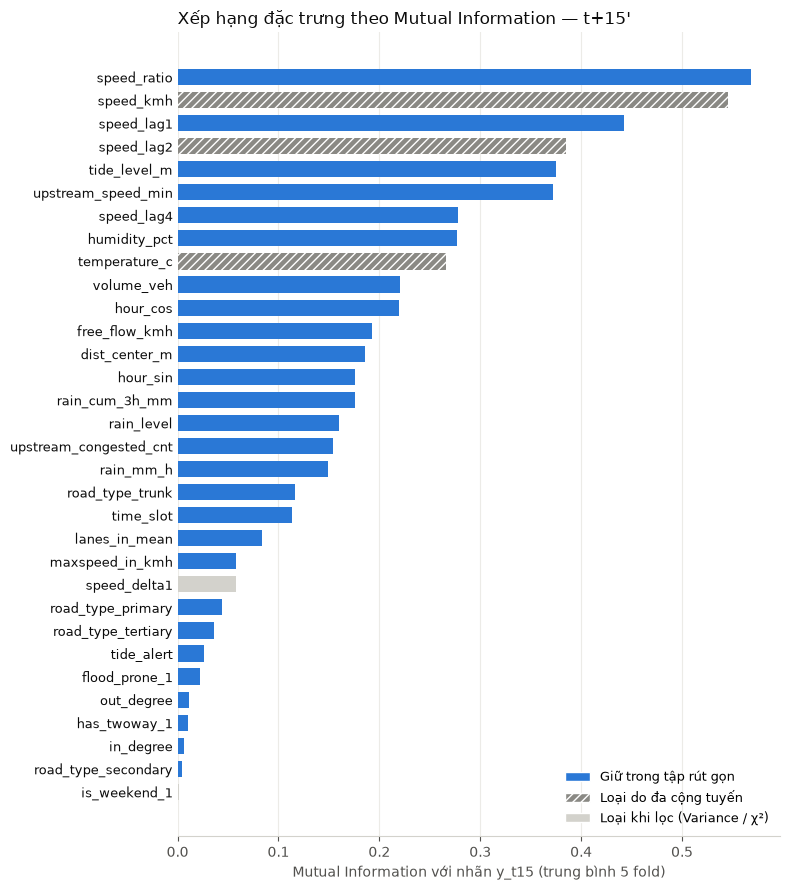

In [9]:
BLUE, GRAY, LIGHT_GRAY, INK, MUTED = "#2a78d6", "#8a8984", "#d3d2cc", "#0b0b0b", "#52514e"

def status(row):
    if not row.selected_final:
        return "Loại khi lọc (Variance / χ²)"
    if row.collinear_dropped:
        return "Loại do đa cộng tuyến"
    return "Giữ trong tập rút gọn"

STYLE = {
    "Giữ trong tập rút gọn": dict(color=BLUE, hatch=None),
    "Loại do đa cộng tuyến": dict(color=GRAY, hatch="////"),
    "Loại khi lọc (Variance / χ²)": dict(color=LIGHT_GRAY, hatch=None),
}

data = ranking[ranking["target"] == "y_t15"].sort_values("mi_mean")
data = data.assign(status=data.apply(status, axis=1))
fig, ax = plt.subplots(figsize=(8, 9))
for y, row in enumerate(data.itertuples()):
    style = STYLE[row.status]
    ax.barh(y, row.mi_mean, height=0.7, color=style["color"], hatch=style["hatch"],
            edgecolor="white", linewidth=0)
ax.set_yticks(range(len(data)), data["feature"], fontsize=9, color=INK)
ax.set_xlabel("Mutual Information với nhãn y_t15 (trung bình 5 fold)", color=MUTED)
ax.set_title("Xếp hạng đặc trưng theo Mutual Information — t+15'", loc="left", color=INK, fontsize=12)
ax.spines[["top", "right", "left"]].set_visible(False)
ax.spines["bottom"].set_color(LIGHT_GRAY)
ax.tick_params(axis="x", colors=MUTED)
ax.tick_params(axis="y", length=0)
ax.xaxis.grid(True, color="#ecebe7", linewidth=0.8)
ax.set_axisbelow(True)
ax.legend(handles=[Patch(facecolor=s["color"], hatch=s["hatch"], label=k, edgecolor="white") for k, s in STYLE.items()],
          loc="lower right", frameon=False, fontsize=9)
plt.tight_layout()
plt.show()

### MI so với SHAP (`[D2]`)

In [10]:
compare = ranking.dropna(subset=["rank_shap"]).groupby("target")[["rank_mi", "rank_shap"]].corr(method="spearman")
print("Spearman(rank MI, rank SHAP):", compare.xs("rank_mi", level=1)["rank_shap"].round(2).to_dict())

group_mi = ranking.groupby(["target", "group"])["mi_mean"].sum().unstack(0)
(group_mi / group_mi.sum() * 100).round(1).sort_values("y_t15", ascending=False).rename_axis("nhóm (% tổng MI)")

Spearman(rank MI, rank SHAP): {'y_t15': 0.54, 'y_t30': 0.48, 'y_t60': 0.59}


target,y_t15,y_t30,y_t60
nhóm (% tổng MI),,,
traffic,43.5,40.0,35.2
static,13.4,15.0,17.2
weather_other,9.5,11.0,13.2
propagation,9.2,8.2,6.8
time,8.9,9.5,9.8
rain,8.5,8.7,9.5
tide,7.0,7.7,8.4


**Đọc kết quả một cách thận trọng:**

1. Hai thước đo trả lời hai câu hỏi khác nhau. MI đo **thông tin riêng lẻ** của từng biến với nhãn. SHAP đo **mức mô hình LightGBM thực sự dùng** biến đó, khi các biến tương quan đã chia nhau phần đóng góp. Vì vậy hai bảng xếp hạng không cần trùng nhau.
2. **MI của `tide_level_m`, `humidity_pct`, `temperature_c` bị thổi phồng trên mock.** Các biến này chỉ có một giá trị cho mỗi mốc thời gian (chung cho 20 nút), và chuỗi chỉ dài 232 mốc (khoảng 2,4 ngày). Một chuỗi trơn như vậy gần như đóng vai trò "đồng hồ", nên MI bắt được nhịp giờ cao điểm qua chúng. SHAP xếp `tide_level_m` thấp hơn hẳn. Cần chạy lại khi có dữ liệu dài hơn (METR-LA `[T1]`) trước khi kết luận về tác động của triều.
3. Kết luận trên **không ảnh hưởng tới quyết định loại biến đa cộng tuyến**: MI chỉ được so sánh *bên trong* từng cặp cùng loại (tốc độ/tỉ lệ, lag1/lag2, nhiệt độ/độ ẩm), nên độ lệch tác động như nhau lên cả hai vế.
4. `rain_cum_3h_mm` đứng thứ 2 theo SHAP nhưng thứ ~15 theo MI: tác động của mưa mang tính **ngưỡng** (chỉ gây kẹt khi mưa lớn kéo dài). Đây đúng là lý do Pearson/MI không được dùng để lọc bỏ biến mưa và triều.

## 7. Nhánh đối chứng PCA

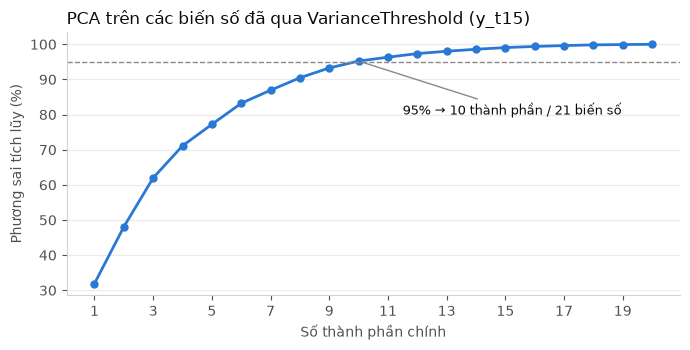

In [11]:
# Fit trên 80% mốc thời gian đầu (train), đúng quy tắc chống rò rỉ.
cut = np.sort(frame["timestamp"].unique())[int(0.8 * frame["timestamp"].nunique())]
train = frame[frame["timestamp"] < cut]
pca_selector = fs.PCAFeatureSelector().fit(train[fs.ALL_FEATURES], train["y_t15"])
cumulative = np.cumsum(pca_selector.pca_.explained_variance_ratio_)

full = fs.PCAFeatureSelector(pca_variance=0.9999).fit(train[fs.ALL_FEATURES], train["y_t15"])
curve = np.cumsum(full.pca_.explained_variance_ratio_)
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(range(1, len(curve) + 1), curve * 100, color=BLUE, linewidth=2, marker="o", markersize=5)
ax.axhline(95, color=GRAY, linewidth=1, linestyle="--")
ax.annotate(f"95% → {len(cumulative)} thành phần / {len(pca_selector.selected_numeric_)} biến số",
            xy=(len(cumulative), cumulative[-1] * 100), xytext=(len(cumulative) + 1.5, 80),
            color=INK, fontsize=9, arrowprops=dict(arrowstyle="-", color=GRAY))
ax.set_xticks(range(1, len(curve) + 1, 2))
ax.set_xlabel("Số thành phần chính", color=MUTED)
ax.set_ylabel("Phương sai tích lũy (%)", color=MUTED)
ax.set_title("PCA trên các biến số đã qua VarianceThreshold (y_t15)", loc="left", color=INK, fontsize=12)
ax.spines[["top", "right"]].set_visible(False)
ax.spines[["left", "bottom"]].set_color(LIGHT_GRAY)
ax.tick_params(colors=MUTED)
ax.yaxis.grid(True, color="#ecebe7", linewidth=0.8)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

## 8. Hướng dẫn dùng cho `[T2]` (ST-GNN / Ensemble — Trung)

* **Mô hình cây (LightGBM / XGBoost) + SHAP:** đặt `fs.FeatureSelector()` vào `Pipeline` (fit lại trong từng fold) hoặc dùng danh sách `selected` của từng nhãn.
* **ST-GNN / GAT:** dùng `selected_compact`, chia sẵn thành `stgnn.dynamic` (theo bước 15') và `stgnn.static` (thuộc tính nút). Ô dưới đây dựng tensor đặc trưng $X \in \mathbb{R}^{T \times N \times F}$ theo thứ tự `node_id` của ma trận kề `adjacency_matrix.csv`. Scaler chỉ được fit trên phần train.
* `upstream_speed_min`, `upstream_congested_cnt`, `in_degree`, `out_degree` là đặc trưng **tổng hợp từ đồ thị bằng tay**. Với GNN, bước truyền thông điệp trên $A$ tự học được thông tin này, nên có thể chạy ablation bỏ 4 cột này để đo lợi ích thực của kiến trúc đồ thị.

In [12]:
features = selected["y_t15"]["stgnn"]["dynamic"] + selected["y_t15"]["stgnn"]["static"]
selector = fs.FeatureSelector().fit(train[fs.ALL_FEATURES], train["y_t15"])  # chỉ để mã hóa One-Hot
encoded = selector.transform(frame[fs.ALL_FEATURES]).assign(timestamp=frame["timestamp"], node_id=frame["node_id"])

adjacency = pd.read_csv(ROOT / "01_data_sample" / "adjacency_matrix.csv", index_col=0)
node_order = [int(n) for n in adjacency.index]
panel = encoded.set_index(["timestamp", "node_id"])[features].sort_index()
timestamps = panel.index.get_level_values(0).unique()
X = panel.reindex(pd.MultiIndex.from_product([timestamps, node_order])).to_numpy().reshape(len(timestamps), len(node_order), len(features))
print("X shape (T, N, F):", X.shape, "| NaN:", int(np.isnan(X).sum()))

X shape (T, N, F): (232, 20, 27) | NaN: 0


## 9. Kết luận

* Đặc trưng **`flood_prone`** (`[H1]`) đã được ghép vào pipeline và vượt ngưỡng $\chi^2$ ở cả 3 mốc dự báo. Đây là biến tĩnh, mã hóa trực tiếp vùng trũng ngập của đề tài.
* Nhánh chính giữ **30/32** cột mã hóa: chỉ loại `speed_delta1` (phương sai thấp) và `is_weekend_1` (không đạt $\chi^2$; mock chỉ có khoảng 2,4 ngày nên gần như không có cuối tuần).
* Tập rút gọn ST-GNN giữ **27/32** cột (giảm 15,6%). Nhánh PCA giảm 40,6% nhưng mất tên biến gốc. **Mục tiêu giảm ≥ 40% số chiều chỉ đạt ở nhánh PCA**: mock dataset được thiết kế ít biến dư thừa, và ép giảm thêm sẽ phải loại các biến mưa/triều mà đề tài cần giải thích.
* **Giới hạn:** toàn bộ kết quả chạy trên mock 4.640 dòng. Khi `[T1]` bàn giao METR-LA và mock đa mức mưa, chỉ cần chạy lại `python 02_feature_selection/01_feature_selection_pipeline.py --data <file.csv>` (dữ liệu METR-LA không có `flood_prone` thì truyền `--nodes` tương ứng hoặc bổ sung cột này).